# Lesson 8: rebuilding a parking picture from fewer patterns

Imagine explaining a photograph by first describing the broad shapes, then adding
smaller details. Singular value decomposition (SVD) writes a grid of image numbers
as weighted patterns. Keeping fewer patterns gives an approximation. A car roof
or shadow can blur together; attractive compression does not prove good detection.

This is a numerical lesson on one real **training** image, not a trained vehicle
model or a new accuracy benchmark. It opens no final images or labels. The picture
is converted to grayscale and resized to256x160 before decomposition; the original
file stays unchanged. The desktop Convolution lab has the same compression tool.


In [1]:
%matplotlib inline
import sys,json,hashlib,html
from pathlib import Path
import numpy as np
from PIL import Image
from IPython.display import display,HTML
ROOT=Path.cwd()
if not (ROOT/'src/smart_parking').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from smart_parking.decomposition import image_factors,rank_report,reconstruct,plot_decomposition
sample=json.loads((ROOT/'configs/demo_sample.json').read_text(encoding='utf-8'))
assert sample['split']=='train'
path=ROOT/sample['image']
assert hashlib.sha256(path.read_bytes()).hexdigest()==sample['image_sha256']
with Image.open(path) as original:image=original.convert('RGB')
factors=image_factors(image)
print('Real source SRC-DS-001:',sample['image'])
print('Teaching matrix:',factors['input'].shape,'Original bytes verified; no final data.')


Real source SRC-DS-001: data/raw/pklot_subset/PKLot/parking2/sunny/2012-09-11/2012-09-11_15_16_58.jpg
Teaching matrix: (160, 256) Original bytes verified; no final data.


## How many numbers do we keep?

For a height H, width W and rank k, the three factors store H*k+k+k*W numbers.
The original grayscale matrix stores H*W numbers. Here all stored numbers have
the same float64 format, so we can compare their memory fairly. This is **not**
the size of the original JPEG, a saved compressed file, or the full application.
At high rank, the factors can take more space than the original matrix.

MSE is the average squared reconstruction error, with grayscale values from0to1.
Retained energy describes these image numbers;98% energy is not98% vehicle accuracy.
Metrics below use the unclipped numerical reconstruction; only the display clips
values to the visible0to1range.


In [2]:
ranks=[1,8,24,48,96,160]
reports=[rank_report(factors,k) for k in ranks]
headers=['Patterns','MSE (lower is better)','Retained energy','Factor memory / matrix']
rows=[[r['rank'],f"{r['mse']:.6f}",f"{r['retained_energy_fraction']:.2%}",f"{r['factor_to_original_float64_ratio']:.2%}"] for r in reports]
markup='<table border="1" cellpadding="6"><tr>'+''.join('<th>'+html.escape(h)+'</th>' for h in headers)+'</tr>'
markup+=''.join('<tr>'+''.join('<td>'+html.escape(str(v))+'</td>' for v in row)+'</tr>' for row in rows)+'</table>'
display(HTML(markup))


Patterns,MSE (lower is better),Retained energy,Factor memory / matrix
1,0.025015,92.63%,1.02%
8,0.009146,97.30%,8.14%
24,0.002752,99.19%,24.43%
48,0.000746,99.78%,48.87%
96,0.000064,99.98%,97.73%
160,0.000000,100.00%,162.89%


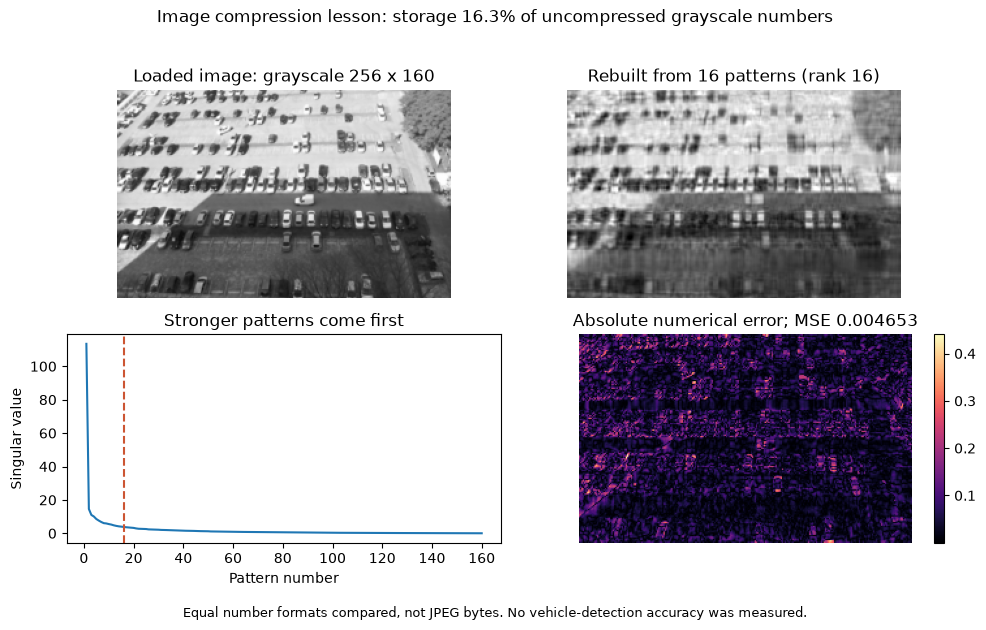

16-pattern factor memory: 53376 bytes
Original grayscale float64 grid: 327680 bytes


In [3]:
import matplotlib.pyplot as plt
fig,report=plot_decomposition(image,16)
plt.show()
print('16-pattern factor memory:',report['factor_float64_bytes'],'bytes')
print('Original grayscale float64 grid:',report['original_float64_bytes'],'bytes')


## Check the algebra

The matrix is reconstructed as U times the diagonal singular-value matrix times
Vh. Keeping only the first k weighted patterns gives `(U[:,:k]*S[:k])@Vh[:k]`.
NumPy supplies the SVD solver; this project implements the bounded lesson, checks,
memory accounting, visual comparison and app/notebook connection. It does not
claim to have written the numerical decomposition solver.


In [4]:
full=rank_report(factors,len(factors['s']))
assert full['max_absolute_error']<1e-10
assert all(a['mse']>=b['mse']-1e-14 for a,b in zip(reports,reports[1:]))
for r in reports:assert abs(r['mse']*factors['input'].size-r['discarded_energy'])<1e-9
assert full['factor_to_original_float64_ratio']>1
assert hashlib.sha256(path.read_bytes()).hexdigest()==sample['image_sha256']
print('Full-pattern maximum numerical error:',full['max_absolute_error'])
print('Error decreases; full-pattern factors use MORE memory; original image is unchanged.')


Full-pattern maximum numerical error: 2.0539125955565396e-14
Error decreases; full-pattern factors use MORE memory; original image is unchanged.


## Try it yourself

Before changing16to8in the plot, predict which car boundaries will become less
clear. Explain why160patterns reconstruct the grid closely but use more memory.
Explain why retained energy cannot establish occupancy accuracy. Your own written
answers and independent changes are still needed; executed cells do not prove mastery.

Sources: PKLot, Almeida et al., CC BY4.0, source SRC-DS-001:
https://web.inf.ufpr.br/vri/databases/parking-lot-database/ . Original local image
and checksum are displayed above. Source SRC-DOC-018, NumPy2.5 SVD API:
https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html .
The picture is a modified grayscale/resized teaching illustration; no endorsement.
Source register/receipts: data/source_manifest.csv and data/resource_receipts.jsonl.
